# HI 5312 | MIMIC-IV Demo: pandas Joins & Clinical Analytics
**Hands-on student workbook** | GitHub Codespaces / Jupyter | No PostgreSQL required

**Learning outcomes:** load compressed CSVs; identify patient, admission and event-level keys; perform safe joins; aggregate before joining; explore diagnoses, labs and ICU utilization; create reproducible project analyses.

**Important:** MIMIC-IV Demo is a small, selected, deidentified teaching sample. Its results are not population estimates or clinical recommendations. Timestamps are deidentified. Work only with approved course data.

## 0. How to use this notebook
Run cells **top to bottom** (Jupyter: *Run All*). A `NameError` often means a preceding setup cell did not run. The setup supports both `.csv` and `.csv.gz` MIMIC-IV Demo files, and searches the usual course Codespace locations. No PostgreSQL connection is required for this pandas notebook.

Most examples use the `hosp` files: `patients`, `admissions`, `diagnoses_icd`, `d_icd_diagnoses`, `labevents`, `d_labitems`, `prescriptions`, `transfers`. ICU examples use `icustays` when available. Some tables are optional; the notebook checks before loading them.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("pandas:", pd.__version__)
print("Current directory:", Path.cwd())

pandas: 3.0.6
Current directory: /workspaces/hi5304-notebooks/learning/hi5312


## 1. Locate and load MIMIC-IV Demo CSVs
The course files may be `.csv` **or** `.csv.gz`. pandas reads either format directly. No database credentials needed. Run both setup cells before continuing.


In [2]:
# Prefer the official course Codespace path; search other workspace locations if needed.
roots = [Path("/workspaces"), Path.cwd()]
known_folders = [
    Path("/workspaces/hi5304-notebooks/data/mimic-iv-demo/hosp"),
    Path("/workspaces/hi5304-notebook/data/mimic-iv-demo/hosp"),
]

def has_patients(folder):
    return any((folder / filename).is_file() for filename in ("patients.csv", "patients.csv.gz"))

candidates = {p.resolve() for p in known_folders if has_patients(p)}
if not candidates:
    for root in roots:
        if root.exists():
            for pattern in ("**/hosp/patients.csv", "**/hosp/patients.csv.gz"):
                candidates.update(p.resolve().parent for p in root.glob(pattern))

candidates = sorted(candidates, key=lambda p: ("hi5304-notebooks" not in p.parts, str(p)))
print("MIMIC hospital folders found:")
for i, folder in enumerate(candidates, 1):
    print(f"  {i}: {folder}")
if not candidates:
    raise FileNotFoundError(
        "Could not find hosp/patients.csv or hosp/patients.csv.gz. "
        "Upload the MIMIC-IV Demo hosp and icu folders under "
        "/workspaces/hi5304-notebooks/data/mimic-iv-demo/."
    )
SELECTED_HOSP_FOLDER = candidates[0]
print("\nSelected:", SELECTED_HOSP_FOLDER)
# If needed, override with: SELECTED_HOSP_FOLDER = Path("/your/path/to/hosp")


MIMIC hospital folders found:
  1: /workspaces/hi5304-notebooks/data/mimic-iv-demo/hosp

Selected: /workspaces/hi5304-notebooks/data/mimic-iv-demo/hosp


In [3]:
hosp = Path(SELECTED_HOSP_FOLDER)
icu = hosp.parent / "icu"

def load_table(name, folder=None, required=True):
    if folder is None:
        folder = hosp
    folder = Path(folder)
    paths = [folder / f"{name}.csv", folder / f"{name}.csv.gz"]
    path = next((p for p in paths if p.is_file()), None)
    if path is None:
        if required:
            raise FileNotFoundError(
                f"Missing required MIMIC table '{name}' in {folder}. "
                "Expected a .csv or .csv.gz file."
            )
        print(f"Optional table not found: {name} ({folder})")
        return None
    result = pd.read_csv(path, low_memory=False)
    print(f"{name}: {result.shape[0]:,} rows x {result.shape[1]} columns ({path.name})")
    return result

patients = load_table("patients")
admissions = load_table("admissions")
print("\nPatient columns:", patients.columns.tolist())
print("Admission columns:", admissions.columns.tolist())
display(patients.head(3), admissions.head(3))


patients: 100 rows x 6 columns (patients.csv)
admissions: 275 rows x 16 columns (admissions.csv)

Patient columns: ['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']
Admission columns: ['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']


,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10014729,F,21,2125,2011 - 2013,NaN
1,10003400,F,72,2134,2011 - 2013,2137-09-02
2,10002428,F,80,2155,2011 - 2013,NaN


,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,ENGLISH,SINGLE,BLACK/CAPE VERDEAN,2196-02-24 12:15:00,2196-02-24 17:07:00,0
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,NaN,URGENT,P41R5N,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,?,MARRIED,HISPANIC/LATINO - PUERTO RICAN,NaN,NaN,0
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,NaN,URGENT,P233F6,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,ENGLISH,MARRIED,WHITE,2134-08-17 16:24:00,2134-08-18 03:15:00,0


## 2. Start with the data grain and join keys
- `subject_id`: one patient; one patient may have multiple hospitalizations.
- `hadm_id`: one hospital admission; an admission may have multiple diagnoses, lab events, transfers, and ICU stays.
- `stay_id`: one ICU stay (when using ICU tables).
- `itemid`: an event/test code; use a dictionary to interpret it.

**Rule:** Decide whether your result should have one row per *patient*, *admission*, *ICU stay*, or *event* **before** merging.

In [4]:
print("Unique patients:", patients.subject_id.nunique())
print("Unique admissions:", admissions.hadm_id.nunique())
print("Admissions per patient (summary):")
display(admissions.groupby("subject_id").hadm_id.nunique().describe())
print("Patient key duplicates:", patients.subject_id.duplicated().sum())
print("Admission key duplicates:", admissions.hadm_id.duplicated().sum())

Unique patients: 100
Unique admissions: 275
Admissions per patient (summary):


count    100.0000
mean       2.7500
std        3.1794
min        1.0000
25%        1.0000
50%        1.0000
75%        3.0000
max       20.0000
Name: hadm_id, dtype: float64

Patient key duplicates: 0
Admission key duplicates: 0


## 3. JOIN #1 — Admissions + patients (many-to-one, LEFT)
Keep every admission, adding patient characteristics. `validate='many_to_one'` catches unexpected duplicate patient keys. `indicator=True` helps audit unmatched records.

In [5]:
patient_admissions = admissions.merge(
    patients, on="subject_id", how="left", validate="many_to_one", indicator=True
)
print("Before:", len(admissions), "After:", len(patient_admissions))
print(patient_admissions["_merge"].value_counts())
assert len(patient_admissions) == len(admissions)
display(patient_admissions[["subject_id", "hadm_id", "anchor_age", "gender", "admission_type"]].head())

Before: 275 After: 275
_merge
both          275
left_only       0
right_only      0
Name: count, dtype: int64


,subject_id,hadm_id,anchor_age,gender,admission_type
0,10004235,24181354,47,M,URGENT
1,10009628,25926192,58,M,URGENT
2,10018081,23983182,79,M,URGENT
3,10006053,22942076,52,M,URGENT
4,10031404,21606243,82,F,URGENT


## 4. JOIN #2 — INNER vs LEFT vs ANTI join
An inner join keeps matched admissions only; a left join keeps all admissions. An anti join finds admission rows without a patient match. These are useful data-quality checks.

In [6]:
inner = admissions.merge(patients[["subject_id", "gender"]], on="subject_id", how="inner", validate="many_to_one")
left = admissions.merge(patients[["subject_id", "gender"]], on="subject_id", how="left", validate="many_to_one", indicator=True)
unmatched = left.loc[left["_merge"] == "left_only"]
print("Inner rows:", len(inner), "Left rows:", len(left), "Unmatched admissions:", len(unmatched))

Inner rows: 275 Left rows: 275 Unmatched admissions: 0


## 5. Admissions analytics — time, length of stay, and readmissions
Calculate length of stay from admission and discharge timestamps. Use the admission-level table, not a lab-event-expanded table, to avoid double counting.

In [7]:
admissions_a = admissions.copy()
for c in ["admittime", "dischtime"]:
    admissions_a[c] = pd.to_datetime(admissions_a[c], errors="coerce")
admissions_a["los_days"] = (admissions_a.dischtime - admissions_a.admittime).dt.total_seconds() / 86400
print(admissions_a.los_days.describe())
display(admissions_a.groupby("admission_type", dropna=False).los_days.agg(["count", "mean", "median"]).round(2).sort_values("count", ascending=False).head(12))

count    275.000000
mean       6.875530
std        6.733832
min        0.046528
25%        2.692014
50%        4.852778
75%        8.768403
max       44.927778
Name: los_days, dtype: float64


,count,mean,median
admission_type,,,
EW EMER.,104,7.28,5.55
OBSERVATION ADMIT,45,8.15,4.85
URGENT,38,9.85,7.86
EU OBSERVATION,30,0.92,0.64
SURGICAL SAME DAY ADMISSION,18,5.70,5.48
DIRECT EMER.,15,9.39,4.09
ELECTIVE,13,8.19,6.19
DIRECT OBSERVATION,7,1.45,1.23
AMBULATORY OBSERVATION,5,1.02,0.98


,subject_id,n_admissions,mean_los_days
0,10000032,4,1.444444
1,10001217,2,6.354514
2,10001725,1,2.994444
3,10002428,7,5.621230
4,10002495,1,6.891667


Patients with >1 admissions: 48


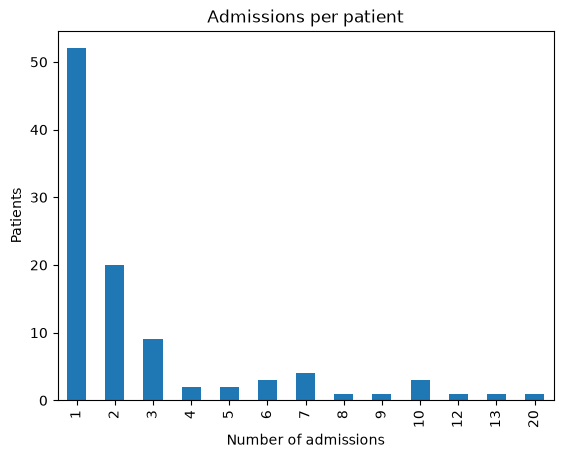

In [8]:
# Number of admissions per patient; note: this is not a validated 30-day readmission measure.
admissions_per_patient = admissions_a.groupby("subject_id").agg(
    n_admissions=("hadm_id", "nunique"),
    mean_los_days=("los_days", "mean")
).reset_index()
display(admissions_per_patient.head())
print("Patients with >1 admissions:", (admissions_per_patient.n_admissions > 1).sum())
admissions_per_patient.n_admissions.value_counts().sort_index().plot(kind="bar", title="Admissions per patient")
plt.xlabel("Number of admissions"); plt.ylabel("Patients"); plt.show()

## 6. JOIN #3 — Patient-level aggregation + patients
First aggregate admissions to one row per `subject_id`, then merge. This preserves one row per patient and is often ideal for student project datasets.

In [9]:
patient_summary = patients.merge(admissions_per_patient, on="subject_id", how="left", validate="one_to_one")
patient_summary["n_admissions"] = patient_summary.n_admissions.fillna(0).astype(int)
assert len(patient_summary) == len(patients)
display(patient_summary[["subject_id", "anchor_age", "gender", "n_admissions", "mean_los_days"]].head())
display(patient_summary.groupby("gender", dropna=False).agg(
    patients=("subject_id", "nunique"), mean_anchor_age=("anchor_age", "mean"), mean_admissions=("n_admissions", "mean")
).round(2))

,subject_id,anchor_age,gender,n_admissions,mean_los_days
0,10014729,21,F,2,8.079514
1,10003400,72,F,7,11.737004
2,10002428,80,F,7,5.621230
3,10032725,38,F,2,15.227778
4,10027445,48,F,3,9.781250


,patients,mean_anchor_age,mean_admissions
gender,,,
F,43,60.81,3.09
M,57,62.46,2.49


## 7. JOIN #4 — Diagnoses + ICD code dictionary (many-to-one)
ICD descriptions require **both** `icd_code` and `icd_version`; joining on the code alone can produce incorrect matches or duplicate rows. `seq_num` represents diagnosis ordering, not severity.

In [10]:
diagnoses = load_table("diagnoses_icd")
icd_dictionary = load_table("d_icd_diagnoses")
print("Diagnosis columns:", diagnoses.columns.tolist())
print("Dictionary columns:", icd_dictionary.columns.tolist())
assert not icd_dictionary.duplicated(["icd_code", "icd_version"]).any()
diagnoses_named = diagnoses.merge(
    icd_dictionary[["icd_code", "icd_version", "long_title"]],
    on=["icd_code", "icd_version"], how="left", validate="many_to_one", indicator=True
)
print(diagnoses_named._merge.value_counts())
assert len(diagnoses_named) == len(diagnoses)
display(diagnoses_named[["subject_id", "hadm_id", "seq_num", "icd_code", "icd_version", "long_title"]].head(8))

diagnoses_icd: 4,506 rows x 5 columns (diagnoses_icd.csv)
d_icd_diagnoses: 109,775 rows x 3 columns (d_icd_diagnoses.csv)
Diagnosis columns: ['subject_id', 'hadm_id', 'seq_num', 'icd_code', 'icd_version']
Dictionary columns: ['icd_code', 'icd_version', 'long_title']
_merge
both          4506
left_only        0
right_only       0
Name: count, dtype: int64


,subject_id,hadm_id,seq_num,icd_code,icd_version,long_title
0,10035185,22580999,3,4139,9,Other and unspecified angina pectoris
1,10035185,22580999,10,V707,9,Examination of participant in clinical trial
2,10035185,22580999,1,41401,9,Coronary atherosclerosis of native coronary ar...
3,10035185,22580999,9,3899,9,Unspecified hearing loss
4,10035185,22580999,11,V8532,9,"Body Mass Index 32.0-32.9, adult"
5,10035185,22580999,2,25002,9,Diabetes mellitus without mention of complicat...
6,10035185,22580999,7,71696,9,"Arthropathy, unspecified, lower leg"
7,10035185,22580999,8,V1083,9,Personal history of other malignant neoplasm o...


## 8. JOIN #5 — Primary diagnosis per admission
Filter to `seq_num == 1` first. Check for duplicate `hadm_id` before merging with admissions. If duplicates appear, inspect rather than silently dropping them.

In [11]:
primary_dx = diagnoses_named.loc[diagnoses_named.seq_num == 1, ["hadm_id", "icd_code", "icd_version", "long_title"]].copy()
print("Primary diagnosis rows:", len(primary_dx))
print("Admissions with multiple primary-diagnosis rows:", primary_dx.hadm_id.duplicated().sum())
if not primary_dx.hadm_id.duplicated().any():
    admissions_dx = admissions_a.merge(primary_dx, on="hadm_id", how="left", validate="one_to_one")
    display(admissions_dx[["hadm_id", "long_title", "los_days"]].head())
else:
    print("Review duplicated hadm_id rows before performing the join.")

Primary diagnosis rows: 275
Admissions with multiple primary-diagnosis rows: 0


,hadm_id,long_title,los_days
0,24181354,Septicemia due to escherichia coli [E. coli],8.975000
1,25926192,Coronary atherosclerosis of native coronary ar...,7.841667
2,23983182,Other postoperative infection,5.731250
3,22942076,Hepatic encephalopathy,1.736806
4,21606243,Other forms of acute pericarditis,2.090972


## 9. JOIN #6 — Diagnosis burden per admission (aggregate then merge)
**Common pitfall:** joining raw diagnoses directly to admissions repeats an admission once per diagnosis. That inflates counts and average lengths of stay if not handled carefully. Aggregate first.

In [12]:
dx_counts = diagnoses.groupby("hadm_id").agg(
    n_diagnosis_rows=("icd_code", "size"),
    n_distinct_icd_codes=("icd_code", "nunique")
).reset_index()
admission_dx_counts = admissions_a.merge(dx_counts, on="hadm_id", how="left", validate="one_to_one")
admission_dx_counts[["n_diagnosis_rows", "n_distinct_icd_codes"]] = admission_dx_counts[["n_diagnosis_rows", "n_distinct_icd_codes"]].fillna(0)
display(admission_dx_counts[["hadm_id", "los_days", "n_diagnosis_rows", "n_distinct_icd_codes"]].head())
print("Spearman association, diagnosis rows vs LOS:", admission_dx_counts[["n_diagnosis_rows", "los_days"]].corr(method="spearman").iloc[0,1])

,hadm_id,los_days,n_diagnosis_rows,n_distinct_icd_codes
0,24181354,8.975000,26,26
1,25926192,7.841667,8,8
2,23983182,5.731250,19,19
3,22942076,1.736806,10,10
4,21606243,2.090972,15,15


Spearman association, diagnosis rows vs LOS: 0.46970134053813734


## 10. Explore diagnoses and code descriptions
Top diagnoses by **unique admissions** (not raw diagnosis rows). Students can modify the search phrase for their research question.

,admissions
long_title,
Unspecified essential hypertension,68
"Hyperlipidemia, unspecified",57
"Acute kidney failure, unspecified",56
Other and unspecified hyperlipidemia,55
"Hypothyroidism, unspecified",47
"Obesity, unspecified",43
"Anemia, unspecified",41
Long term (current) use of insulin,37
"Urinary tract infection, site not specified",36


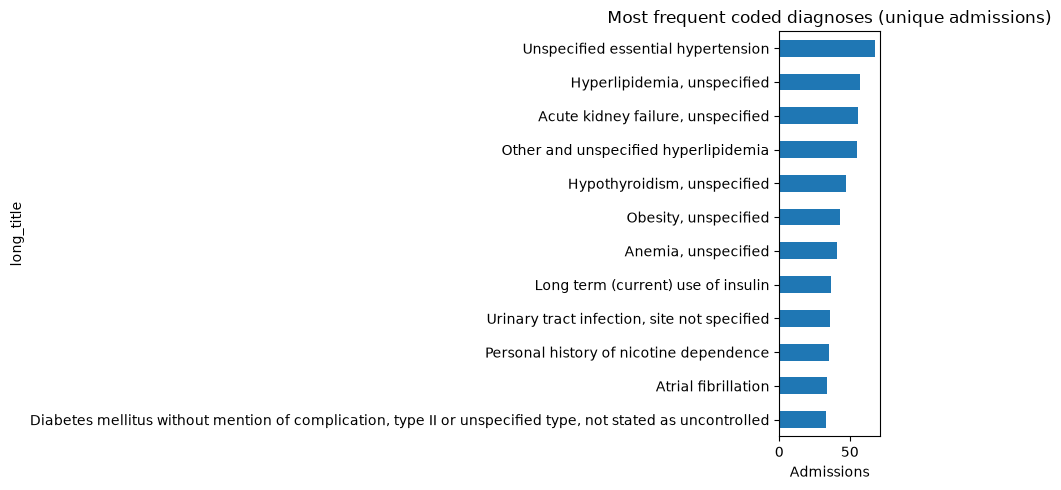

In [13]:
top_dx = (diagnoses_named.dropna(subset=["long_title"])
          .groupby("long_title").hadm_id.nunique().sort_values(ascending=False).head(12))
display(top_dx.rename("admissions").to_frame())
top_dx.sort_values().plot(kind="barh", figsize=(9,5), title="Most frequent coded diagnoses (unique admissions)")
plt.xlabel("Admissions"); plt.tight_layout(); plt.show()

In [14]:
# Exploratory case-finding using text: useful for learning, not a validated clinical phenotype.
phrase = "diabetes"
selected = diagnoses_named[diagnoses_named.long_title.str.contains(phrase, case=False, na=False)]
print(f"Admissions with a diagnosis description containing '{phrase}':", selected.hadm_id.nunique())
print("Unique patients:", selected.subject_id.nunique())
display(selected[["icd_code", "icd_version", "long_title"]].drop_duplicates().head(15))

Admissions with a diagnosis description containing 'diabetes': 115
Unique patients: 35


,icd_code,icd_version,long_title
5,25002,9,Diabetes mellitus without mention of complicat...
80,25050,9,"Diabetes with ophthalmic manifestations, type ..."
88,E119,10,Type 2 diabetes mellitus without complications
160,25000,9,Diabetes mellitus without mention of complicat...
273,25012,9,"Diabetes with ketoacidosis, type II or unspeci..."
901,E118,10,Type 2 diabetes mellitus with unspecified comp...
966,E1165,10,Type 2 diabetes mellitus with hyperglycemia
984,E1010,10,Type 1 diabetes mellitus with ketoacidosis wit...
1170,E1122,10,Type 2 diabetes mellitus with diabetic chronic...
1415,E1140,10,Type 2 diabetes mellitus with diabetic neuropa...


## 11. JOIN #7 — Laboratory events + lab dictionary
`labevents` is event-level data. Use `itemid` to attach test labels; use `valuenum` for numeric measurements. Units and specimen fluid matter. Avoid treating every laboratory observation as independent.

In [15]:
labs = load_table("labevents")
lab_items = load_table("d_labitems")
print("Lab columns:", labs.columns.tolist())
print("Lab dictionary columns:", lab_items.columns.tolist())
assert lab_items.itemid.is_unique
labs_named = labs.merge(lab_items[["itemid", "label", "fluid", "category"]], on="itemid", how="left", validate="many_to_one")
assert len(labs_named) == len(labs)
display(labs_named[["subject_id", "hadm_id", "itemid", "label", "fluid", "valuenum", "valueuom"]].head())

labevents: 107,727 rows x 16 columns (labevents.csv)
d_labitems: 1,622 rows x 4 columns (d_labitems.csv)
Lab columns: ['labevent_id', 'subject_id', 'hadm_id', 'specimen_id', 'itemid', 'order_provider_id', 'charttime', 'storetime', 'value', 'valuenum', 'valueuom', 'ref_range_lower', 'ref_range_upper', 'flag', 'priority', 'comments']
Lab dictionary columns: ['itemid', 'label', 'fluid', 'category']


,subject_id,hadm_id,itemid,label,fluid,valuenum,valueuom
0,10014354,29600294.0,51277,RDW,Blood,15.40,%
1,10014354,29600294.0,51279,Red Blood Cells,Blood,3.35,m/uL
2,10014354,29600294.0,52172,RDW-SD,Blood,49.70,fL
3,10014354,29600294.0,51301,White Blood Cells,Blood,20.30,K/uL
4,10014354,29600294.0,51249,MCHC,Blood,31.10,g/dL


## 12. Explore lab test frequency and missingness
Count distinct patients and admissions rather than only event rows.

In [16]:
lab_frequency = (labs_named.groupby(["itemid", "label"], dropna=False)
                 .agg(events=("itemid", "size"), patients=("subject_id", "nunique"), admissions=("hadm_id", "nunique"))
                 .sort_values("events", ascending=False).head(15))
display(lab_frequency)
print("Missing numeric values:", labs_named.valuenum.isna().mean().round(3))

,,events,patients,admissions
itemid,label,,,
50971,Potassium,3022,100,250
50983,Sodium,3007,100,250
50912,Creatinine,3003,100,250
50902,Chloride,2981,100,250
51006,Urea Nitrogen,2974,100,250
51221,Hematocrit,2913,100,248
50882,Bicarbonate,2863,100,246
50868,Anion Gap,2860,100,246
51265,Platelet Count,2827,100,248


Missing numeric values: 0.116


## 13. JOIN #8 — One laboratory summary per admission
Find the exact test label and specimen, check units, then aggregate per `hadm_id`. Here we illustrate **Creatinine**; inspect the labels before relying on this selection.

In [17]:
creatinine_tests = lab_items[lab_items.label.str.fullmatch("Creatinine", case=False, na=False)]
display(creatinine_tests[["itemid", "label", "fluid", "category"]])
serum_ids = creatinine_tests.loc[creatinine_tests.fluid.eq("Blood"), "itemid"]
creatinine = labs_named[labs_named.itemid.isin(serum_ids)].copy()
print("Units:", creatinine.valueuom.value_counts(dropna=False).to_dict())
creatinine["valuenum"] = pd.to_numeric(creatinine.valuenum, errors="coerce")
creatinine_summary = (creatinine.dropna(subset=["hadm_id", "valuenum"])
    .groupby("hadm_id").agg(n_creatinine=("valuenum", "size"), mean_creatinine=("valuenum", "mean"), max_creatinine=("valuenum", "max"))
    .reset_index())
clinical_admissions = admissions_a.merge(creatinine_summary, on="hadm_id", how="left", validate="one_to_one")
assert len(clinical_admissions) == len(admissions_a)
display(clinical_admissions[["hadm_id", "los_days", "n_creatinine", "mean_creatinine", "max_creatinine"]].head())

,itemid,label,fluid,category
355,50912,Creatinine,Blood,Chemistry
362,52546,Creatinine,Blood,Chemistry


Units: {'mg/dL': 3003}


,hadm_id,los_days,n_creatinine,mean_creatinine,max_creatinine
0,24181354,8.975000,23.0,3.465217,7.9
1,25926192,7.841667,7.0,0.885714,1.0
2,23983182,5.731250,10.0,0.940000,1.2
3,22942076,1.736806,5.0,2.060000,2.6
4,21606243,2.090972,2.0,0.600000,0.6


## 14. JOIN #9 — Prescriptions + admissions (event-to-admission)
Medication orders are not proof of administration or adherence. Use this example to identify hospital admissions with recorded prescription orders. Aggregate first to preserve admission-level rows.

In [18]:
prescriptions = load_table("prescriptions", required=False)
if prescriptions is not None:
    print("Columns:", prescriptions.columns.tolist())
    display(prescriptions.head(3))
    med_summary = prescriptions.groupby("hadm_id").agg(
        n_prescription_rows=("hadm_id", "size"),
        n_unique_drug_names=("drug", "nunique")
    ).reset_index()
    admission_medications = admissions_a.merge(med_summary, on="hadm_id", how="left", validate="one_to_one")
    display(admission_medications[["hadm_id", "los_days", "n_prescription_rows", "n_unique_drug_names"]].head())

prescriptions: 18,087 rows x 21 columns (prescriptions.csv)
Columns: ['subject_id', 'hadm_id', 'pharmacy_id', 'poe_id', 'poe_seq', 'order_provider_id', 'starttime', 'stoptime', 'drug_type', 'drug', 'formulary_drug_cd', 'gsn', 'ndc', 'prod_strength', 'form_rx', 'dose_val_rx', 'dose_unit_rx', 'form_val_disp', 'form_unit_disp', 'doses_per_24_hrs', 'route']


,subject_id,hadm_id,pharmacy_id,poe_id,poe_seq,order_provider_id,starttime,stoptime,drug_type,drug,formulary_drug_cd,gsn,ndc,prod_strength,form_rx,dose_val_rx,dose_unit_rx,form_val_disp,form_unit_disp,doses_per_24_hrs,route
0,10027602,28166872,27168639,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Fentanyl Citrate,FENT2I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10027602,28166872,40720238,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Fentanyl Citrate,FENT2I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10027602,28166872,62845687,NaN,NaN,NaN,2201-10-31 12:00:00,NaN,MAIN,Lorazepam,LORA2I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,hadm_id,los_days,n_prescription_rows,n_unique_drug_names
0,24181354,8.975000,195.0,65.0
1,25926192,7.841667,166.0,58.0
2,23983182,5.731250,59.0,25.0
3,22942076,1.736806,63.0,28.0
4,21606243,2.090972,34.0,17.0


## 15. JOIN #10 — ICU stays + admissions (one-to-many)
ICU stays have their own `stay_id`. A hospitalization may have multiple ICU stays, so merging raw ICU stays to admissions may produce multiple rows per admission. First inspect the counts.

In [19]:
icu_stays = load_table("icustays", folder=icu, required=False)
if icu_stays is not None:
    print("ICU stay columns:", icu_stays.columns.tolist())
    display(icu_stays.head(3))
    print("ICU stays per admission:")
    display(icu_stays.groupby("hadm_id").stay_id.nunique().describe())
    icu_summary = icu_stays.groupby("hadm_id").agg(
        n_icu_stays=("stay_id", "nunique"),
        total_icu_los_days=("los", "sum")
    ).reset_index()
    admissions_icu = admissions_a.merge(icu_summary, on="hadm_id", how="left", validate="one_to_one")
    admissions_icu["n_icu_stays"] = admissions_icu.n_icu_stays.fillna(0).astype(int)
    admissions_icu["had_icu_stay"] = admissions_icu.n_icu_stays.gt(0)
    print(admissions_icu.groupby("had_icu_stay").los_days.agg(["count", "mean", "median"]).round(2))

icustays: 140 rows x 8 columns (icustays.csv)
ICU stay columns: ['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit', 'intime', 'outtime', 'los']


,subject_id,hadm_id,stay_id,first_careunit,last_careunit,intime,outtime,los
0,10018328,23786647,31269608,Neuro Stepdown,Neuro Stepdown,2154-04-24 23:03:44,2154-05-02 15:55:21,7.702512
1,10020187,24104168,37509585,Neuro Surgical Intensive Care Unit (Neuro SICU),Neuro Stepdown,2169-01-15 04:56:00,2169-01-20 15:47:50,5.452662
2,10020187,26842957,32554129,Neuro Intermediate,Neuro Intermediate,2170-02-24 18:18:46,2170-02-25 15:15:26,0.872685


ICU stays per admission:


count    128.000000
mean       1.093750
std        0.385515
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        4.000000
Name: stay_id, dtype: float64

              count  mean  median
had_icu_stay                     
False           147  4.87    3.26
True            128  9.18    6.92


## 16. JOIN #11 — Multi-table admission-level research dataset
Combine independently aggregated patient, diagnosis, lab and ICU features. The final result should still contain **one row per admission**. This is a strong template for student capstone projects.

In [20]:
project_df = admissions_a.merge(
    patients[["subject_id", "gender", "anchor_age"]], on="subject_id", how="left", validate="many_to_one"
).merge(
    dx_counts, on="hadm_id", how="left", validate="one_to_one"
).merge(
    creatinine_summary, on="hadm_id", how="left", validate="one_to_one"
)
if icu_stays is not None:
    project_df = project_df.merge(icu_summary, on="hadm_id", how="left", validate="one_to_one")
assert len(project_df) == len(admissions)
assert project_df.hadm_id.is_unique
print("Final project dataset:", project_df.shape)
display(project_df.head())

Final project dataset: (275, 26)


,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag,los_days,gender,anchor_age,n_diagnosis_rows,n_distinct_icd_codes,n_creatinine,mean_creatinine,max_creatinine,n_icu_stays,total_icu_los_days
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,ENGLISH,SINGLE,BLACK/CAPE VERDEAN,2196-02-24 12:15:00,2196-02-24 17:07:00,0,8.975000,M,47,26,26,23.0,3.465217,7.9,1.0,4.952106
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,NaN,URGENT,P41R5N,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,?,MARRIED,HISPANIC/LATINO - PUERTO RICAN,NaN,NaN,0,7.841667,M,58,8,8,7.0,0.885714,1.0,1.0,2.280752
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,NaN,URGENT,P233F6,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,ENGLISH,MARRIED,WHITE,2134-08-17 16:24:00,2134-08-18 03:15:00,0,5.731250,M,79,19,19,10.0,0.940000,1.2,NaN,NaN
3,10006053,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,P38TI6,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,NaN,NaN,1,1.736806,M,52,10,10,5.0,2.060000,2.6,2.0,1.775093
4,10031404,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,NaN,URGENT,P07HDB,TRANSFER FROM HOSPITAL,HOME,Other,ENGLISH,WIDOWED,WHITE,NaN,NaN,0,2.090972,F,82,15,15,2.0,0.600000,0.6,1.0,1.206481


## 17. Exploratory analysis: distributions, associations, and missingness
Descriptive analysis is not causal inference. Small demo samples can give unstable results, and repeated hospitalizations from the same patient are not independent.

In [21]:
numeric = [c for c in ["anchor_age", "los_days", "n_diagnosis_rows", "n_creatinine", "mean_creatinine", "n_icu_stays"] if c in project_df]
display(project_df[numeric].describe().T.round(2))
display(project_df[numeric].isna().mean().mul(100).round(1).rename("percent_missing").to_frame())
if len(numeric) >= 2:
    display(project_df[numeric].corr(method="spearman").round(2))

,count,mean,std,min,25%,50%,75%,max
anchor_age,275.0,61.04,14.44,21.00,52.50,60.00,70.00,91.00
los_days,275.0,6.88,6.73,0.05,2.69,4.85,8.77,44.93
n_diagnosis_rows,275.0,16.39,9.01,2.00,9.00,14.00,23.00,39.00
n_creatinine,250.0,9.46,10.63,1.00,3.00,6.00,11.00,61.00
mean_creatinine,250.0,1.41,1.47,0.23,0.67,0.90,1.48,11.62
n_icu_stays,128.0,1.09,0.39,1.00,1.00,1.00,1.00,4.00


,percent_missing
anchor_age,0.0
los_days,0.0
n_diagnosis_rows,0.0
n_creatinine,9.1
mean_creatinine,9.1
n_icu_stays,53.5


,anchor_age,los_days,n_diagnosis_rows,n_creatinine,mean_creatinine,n_icu_stays
anchor_age,1.00,0.01,0.25,0.01,0.14,0.06
los_days,0.01,1.00,0.47,0.89,0.04,0.21
n_diagnosis_rows,0.25,0.47,1.00,0.56,0.41,0.23
n_creatinine,0.01,0.89,0.56,1.00,0.17,0.21
mean_creatinine,0.14,0.04,0.41,0.17,1.00,0.10
n_icu_stays,0.06,0.21,0.23,0.21,0.10,1.00


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
project_df["los_days"].dropna().hist(bins=20, ax=ax)
ax.set(title="Hospital length of stay", xlabel="Days", ylabel="Admissions")
plt.tight_layout(); plt.show()

## 18. JOIN #12 — Self-join / sequence analysis: time to next admission
A **self-join-like** analysis uses multiple rows from the same admission table. Sort each patient's admissions, then use `groupby().shift()` to access the next admission. A simplistic 30-day indicator is for teaching only: it does not establish a validated readmission quality measure.

In [22]:
sequence = admissions_a.sort_values(["subject_id", "admittime", "hadm_id"]).copy()
sequence["next_admittime"] = sequence.groupby("subject_id")["admittime"].shift(-1)
sequence["days_to_next_admission"] = (sequence.next_admittime - sequence.dischtime).dt.total_seconds() / 86400
sequence["next_within_30_days"] = sequence.days_to_next_admission.between(0, 30, inclusive="both")
display(sequence[["subject_id", "hadm_id", "dischtime", "next_admittime", "days_to_next_admission", "next_within_30_days"]].head(12))
print("Admissions followed by another within 30 days (simplified):", sequence.next_within_30_days.sum())

,subject_id,hadm_id,dischtime,next_admittime,days_to_next_admission,next_within_30_days
18,10000032,22595853,2180-05-07 17:15:00,2180-06-26 18:27:00,50.050000,False
103,10000032,22841357,2180-06-27 18:49:00,2180-07-23 12:35:00,25.740278,True
105,10000032,29079034,2180-07-25 17:55:00,2180-08-05 23:44:00,11.242361,True
104,10000032,25742920,2180-08-07 17:50:00,NaT,NaN,False
65,10001217,24597018,2157-11-25 18:00:00,2157-12-18 16:58:00,22.956944,True
157,10001217,27703517,2157-12-24 14:55:00,NaT,NaN,False
64,10001725,25563031,2110-04-14 15:00:00,NaT,NaN,False
198,10002428,25797028,2155-07-15 18:37:00,2156-04-12 14:16:00,271.818750,False
152,10002428,28662225,2156-04-29 16:26:00,2156-04-30 20:35:00,1.172917,True
153,10002428,20321825,2156-05-03 16:36:00,2156-05-11 14:49:00,7.925694,True


Admissions followed by another within 30 days (simplified): 53


## 19. Optional: JOIN #13 — Transfers and admissions
Transfer records may have many rows per admission. Group by admission to calculate the number of location/transfer records, then merge into an admission-level table.

In [ ]:
transfers = load_table("transfers", required=False)
if transfers is not None:
    transfer_summary = transfers.dropna(subset=["hadm_id"]).groupby("hadm_id").agg(
        n_transfer_records=("hadm_id", "size")
    ).reset_index()
    admissions_transfers = admissions_a.merge(transfer_summary, on="hadm_id", how="left", validate="one_to_one")
    display(admissions_transfers[["hadm_id", "los_days", "n_transfer_records"]].head())

## 20. Data quality checklist: verify every join
Ask: What is my unit of analysis? Are join keys unique on the expected side? Did my row count change? Are there unmatched keys? Do missing values have a clinical or technical explanation?

In [ ]:
checks = pd.DataFrame([
    {"table": "patients", "rows": len(patients), "unique_subject_id": patients.subject_id.nunique(), "unique_hadm_id": np.nan},
    {"table": "admissions", "rows": len(admissions), "unique_subject_id": admissions.subject_id.nunique(), "unique_hadm_id": admissions.hadm_id.nunique()},
    {"table": "diagnoses", "rows": len(diagnoses), "unique_subject_id": diagnoses.subject_id.nunique(), "unique_hadm_id": diagnoses.hadm_id.nunique()},
    {"table": "labs", "rows": len(labs), "unique_subject_id": labs.subject_id.nunique(), "unique_hadm_id": labs.hadm_id.nunique()},
    {"table": "project_df", "rows": len(project_df), "unique_subject_id": project_df.subject_id.nunique(), "unique_hadm_id": project_df.hadm_id.nunique()},
])
display(checks)
assert len(project_df) == admissions.hadm_id.nunique(), "Unexpected duplicate admissions in project dataset"

## 21. Export an analysis-ready dataset
This saves to the current notebook directory. Do not publish patient-level data from restricted datasets. This demo is intended for instruction.

In [ ]:
output_path = Path.cwd() / "mimic_demo_admission_analytics.csv"
project_df.to_csv(output_path, index=False)
print("Saved:", output_path)

## 22. Student project ideas and exercises
**Choose a question and define your unit of analysis before coding.**

1. **Hospital utilization:** Compare length of stay by admission type, report counts and medians.
2. **Patient characteristics:** How does anchor age relate to number of admissions? Use a patient-level table.
3. **Diagnosis patterns:** Identify the top ICD descriptions by unique admissions; compare ICD-9 and ICD-10 coding.
4. **Diagnosis burden:** Is the number of coded diagnoses associated with length of stay? Discuss coding bias.
5. **Laboratory utilization:** Which tests are most frequently ordered? Compare event counts, patient counts, and admission counts.
6. **Creatinine and length of stay:** Summarize blood creatinine measurements by admission, check units and missingness, then explore association with LOS.
7. **Medication utilization:** Compare prescription-order counts across admissions. Explain why orders are not medication administrations.
8. **ICU utilization:** Compare admissions with and without an ICU stay; avoid interpreting the association as causal.
9. **Readmission sequences:** Calculate days to the next admission; describe why this is not a validated quality measure.
10. **Data quality audit:** Find unmatched keys, missing variables, repeated records and potential many-to-many joins.

**Required project deliverables:** research question, data dictionary, unit of analysis, join diagram, code with validation checks, descriptive table, at least one figure, limitations paragraph, and reproducible notebook.

## 23. Independent practice: fill in the blanks
Try these without looking back. Then compare the row counts before and after joining.

In [ ]:
# Exercise A: One row per patient with admission counts
# patient_counts = admissions.groupby("________")["________"].nunique().reset_index(name="n_admissions")

# Exercise B: LEFT join patient age onto admissions
# result = admissions.merge(patients[["subject_id", "anchor_age"]], on="________", how="________", validate="many_to_one")

# Exercise C: Mean LOS by admission type
# admissions_a.groupby("________")["________"].mean()

# Exercise D: Why would joining raw labevents to admissions change the number of rows?
# Write your explanation in a Markdown cell.

## 24. Reflection and interpretation
- How does the choice of **patient** vs **admission** vs **event** as the unit of analysis change the answer?
- What is the difference between `inner`, `left`, and `outer` joins?
- Why should we merge ICD code dictionaries on both code and version?
- What errors arise when one admission has dozens of lab measurements?
- What are the risks of drawing conclusions from a small, deidentified demo dataset?

**Source:** PhysioNet, *MIMIC-IV Clinical Database Demo* (use the version supplied in your course Codespace): https://physionet.org/content/mimic-iv-demo/2.2/ . See the dataset documentation for variable definitions and data-use guidance.